<a href="https://colab.research.google.com/github/ahmadmukhtasor-0309-lgtm/Tugas-Machine-Learning/blob/main/Reduksi_Dimensi_PCA_tSNE_LDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 11 - Reduksi Dimensi (PCA, t-SNE, LDA)


## Contoh Perhitungan

In [1]:
import numpy as np

Sigma = np.array([[2.0, 0.8],
                  [0.8, 1.0]])
eigvals = np.sort(np.linalg.eigvalsh(Sigma))[::-1]
print("Eigenvalue:", np.round(eigvals, 3))                      # 2.443, 0.557
print("Explained variance ratio:", np.round(eigvals / eigvals.sum(), 3))  # 0.814, 0.186

Eigenvalue: [2.443 0.557]
Explained variance ratio: [0.814 0.186]


## Persiapan Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

## Import Dataset

In [3]:
digits = load_digits()
X, y = digits.data, digits.target
print("Dimensi data asli:", X.shape)

Dimensi data asli: (1797, 64)


#Preprocessing

In [4]:
X_scaled = StandardScaler().fit_transform(X)

## Training Model (PCA, t-SNE, LDA)

In [5]:
pca = PCA(n_components=0.90)
X_pca = pca.fit_transform(X_scaled)
print("Jumlah komponen untuk 90% variance:",
      pca.n_components_)

X_tsne = TSNE(n_components=2, perplexity=30,
              random_state=42).fit_transform(X_scaled)

lda = LinearDiscriminantAnalysis(n_components=2)
X_lda = lda.fit_transform(X_scaled,
        y)

Jumlah komponen untuk 90% variance: 31


## Evaluasi

In [6]:
print("Explained variance ratio (5 komponen pertama):",
      np.round(pca.explained_variance_ratio_[:5], 3))
print("Total variance dijelaskan:",
      round(pca.explained_variance_ratio_.sum(), 3))

Explained variance ratio (5 komponen pertama): [0.12  0.096 0.084 0.065 0.049]
Total variance dijelaskan: 0.9


## Visualisasi

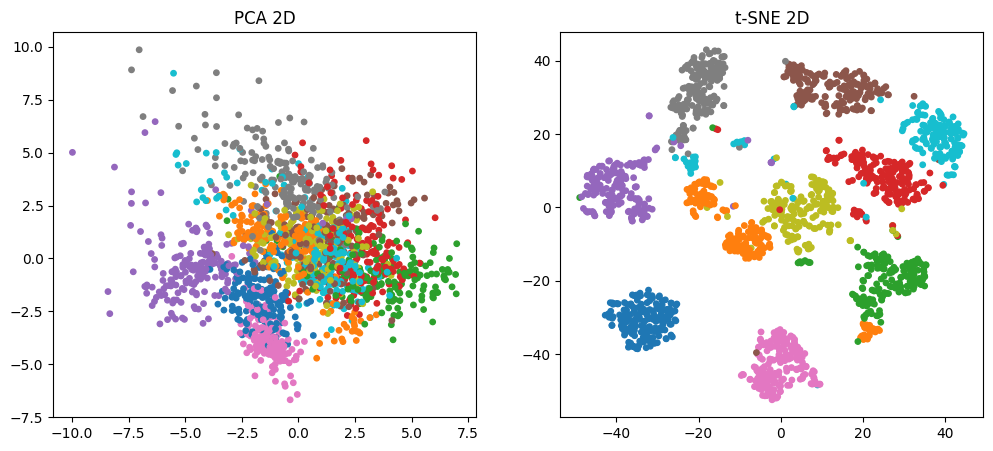

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap="tab10",
                s=15)
axes[0].set_title("PCA 2D")
axes[1].scatter(X_tsne[:, 0], X_tsne[:, 1], c=y, cmap="tab10",
                s=15)
axes[1].set_title("t-SNE 2D")
plt.show()

### Interpretasi
PCA dengan `n_components=0.90` otomatis memilih jumlah komponen minimum yang menjelaskan setidaknya 90% variance (di sini **31 dari 64 dimensi**), sehingga dimensi berkurang tanpa kehilangan banyak informasi. Secara visual, t-SNE menghasilkan pemisahan cluster yang lebih tegas dibanding PCA, namun PCA lebih cocok digunakan ketika hasil reduksi perlu diterapkan pada data baru (mis. sebagai preprocessing sebelum klasifikasi).

---
# Kompresi Dimensi dengan PCA


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_train, X_test, y_train, y_test = train_test_split(X_scaled,
        y, test_size=0.2, random_state=42)

for n_comp in [0.80, 0.90, 0.95, None]:
    pca_i = PCA(n_components=n_comp) if n_comp else PCA()
    X_train_p = pca_i.fit_transform(X_train)
    X_test_p = pca_i.transform(X_test)
    model = LogisticRegression(max_iter=2000).fit(X_train_p,
            y_train)
    acc = accuracy_score(y_test, model.predict(X_test_p))
    print(f"n_components={n_comp}: dimensi={X_train_p.shape[1]}, "
          f"akurasi={acc:.3f}")

n_components=0.8: dimensi=21, akurasi=0.947
n_components=0.9: dimensi=31, akurasi=0.958
n_components=0.95: dimensi=40, akurasi=0.964
n_components=None: dimensi=64, akurasi=0.972


**Pembanding (tanpa PCA)** – untuk menilai dampak kompresi terhadap akurasi:

In [9]:
base = LogisticRegression(max_iter=2000).fit(X_train, y_train)
print(f"Tanpa PCA: dimensi={X_train.shape[1]}, "
      f"akurasi={accuracy_score(y_test, base.predict(X_test)):.3f}")

Tanpa PCA: dimensi=64, akurasi=0.972


### Analisanya
Hasil (`test_size=0.2`, `random_state=42`):

| Konfigurasi | Dimensi | Akurasi |
|---|---|---|
| PCA 80% variance | 21 | 0,947 |
| PCA 90% variance | 31 | 0,958 |
| PCA 95% variance | 40 | 0,964 |
| PCA semua komponen (`None`) | 64 | 0,972 |
| Tanpa PCA (pembanding) | 64 | 0,972 |

- Semakin banyak variance yang dipertahankan, akurasi semakin tinggi. Dengan semua komponen, akurasi sama dengan tanpa PCA karena PCA penuh hanya merotasi data tanpa membuang informasi.
- Kompresi ke 21 dimensi (turun ±67%) hanya menurunkan akurasi ±2,5 poin persentase; ke 31 dimensi (turun ±52%) ±1,4 poin; ke 40 dimensi (turun ±37%) ±0,8 poin.
- **Jumlah komponen optimal:** 90% variance (31 komponen) atau 95% (40 komponen) memberikan keseimbangan terbaik antara efisiensi dimensi dan akurasi. Pilih 95% jika akurasi lebih diutamakan, 90% jika efisiensi lebih diutamakan. Jika akurasi maksimum yang dikejar, gunakan semua komponen.

---
# Perbandingan PCA, t-SNE, dan LDA


In [ ]:
X_pca2 = PCA(n_components=2).fit_transform(X_scaled)
X_tsne2 = TSNE(n_components=2, perplexity=30,
               random_state=42).fit_transform(X_scaled)
X_lda2 = LinearDiscriminantAnalysis(n_components=2).fit_transform(X_scaled, y)

hasil_2d = {"PCA 2D": X_pca2, "t-SNE 2D": X_tsne2, "LDA 2D": X_lda2}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, (nama, Z) in zip(axes, hasil_2d.items()):
    sc = ax.scatter(Z[:, 0], Z[:, 1], c=y, cmap="tab10", s=15)
    for k in range(10):
        c = Z[y == k].mean(axis=0)
        ax.text(c[0], c[1], str(k), fontsize=14, weight="bold")
    ax.set_title(nama)
    ax.set_xlabel("Komponen 1")
    ax.set_ylabel("Komponen 2")
plt.show()

**Pengukuran kuantitatif kualitas pemisahan kelas** (silhouette score dan akurasi k-NN pada data 2D):

In [ ]:
from sklearn.metrics import silhouette_score
from sklearn.neighbors import KNeighborsClassifier

for nama, Z in hasil_2d.items():
    sil = silhouette_score(Z, y)
    Z_tr, Z_te, y_tr, y_te = train_test_split(
        Z, y, test_size=0.2, random_state=42, stratify=y)
    acc = KNeighborsClassifier(n_neighbors=5).fit(Z_tr, y_tr).score(Z_te, y_te)
    print(f"{nama:9s} silhouette={sil:.3f}  akurasi k-NN={acc:.3f}")

### Analisanya
| Metode | Silhouette | Akurasi k-NN (2D) |
|---|---|---|
| PCA 2D | 0,055 | 0,528 |
| t-SNE 2D | 0,485 | 0,967 |
| LDA 2D | 0,188 | 0,669 |

**PCA (unsupervised, linear).** Dua komponen pertama hanya menjelaskan ±21,6% variance sehingga sebagian besar kelas bertumpuk di tengah plot. Hanya digit 0, 4, dan 6 yang agak terpisah di tepi. Pemisahan kelas paling buruk, karena PCA memaksimalkan variance, bukan keterpisahan kelas.

**t-SNE (unsupervised, non-linear).** Pemisahan paling baik: kesepuluh digit membentuk cluster yang kompak dan terpisah jelas, dengan sedikit tumpang tindih pada beberapa titik (mis. sebagian digit 3 dan 8 berdekatan) dan beberapa kelas terpecah menjadi sub-cluster kecil. Kekurangannya: jarak antar-cluster dan ukuran cluster tidak bermakna secara global, hasil bergantung pada `perplexity` dan `random_state`, komputasi lebih lambat, dan tidak bisa langsung mentransformasi data baru, sehingga cocok untuk visualisasi, bukan preprocessing.

**LDA (supervised, linear).** Menggunakan label `y` untuk memaksimalkan jarak antar-kelas relatif terhadap sebaran dalam-kelas. Hasilnya lebih baik daripada PCA: digit 0, 4, dan 6 terpisah jelas, tetapi digit 1, 7, 8 dan 5, 9 masih menumpuk di tengah. Hanya 2 dari maksimal 9 komponen diskriminan yang digunakan dan batasnya linear, sehingga masih di bawah t-SNE. Karena memakai label, hasil LDA bersifat optimistis (tidak setara dengan metode unsupervised).

